# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Other
from IPython.display import display, Markdown

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

# Data Cleaning

In [3]:
def data_structure(df):
    display(Markdown("## Dataset head"))
    display(df.head())
    display(Markdown("## Shape"))
    print(df.shape)
    display(Markdown("## Info"))
    print(df.info())
    display(Markdown("## Describe"))
    display(df.describe())
    display(Markdown("## Unique values"))
    print(df.nunique())
    display(Markdown("## Null"))
    print(df.isnull().sum())
    display(df[df.isna().any(axis=1)])
    display(Markdown("## Duplicates"))
    print(df.duplicated().sum())
    display(df[df.duplicated()])

In [4]:
data_structure(df_raw)

## Dataset head

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other
0,0,0,18,0,0,0,4,4,2,2,...,0,0,0,0,1,0,0,0,1,0
1,0,0,17,0,0,1,1,1,1,2,...,0,0,1,0,0,0,0,0,0,0
2,0,0,15,0,1,1,1,1,1,2,...,0,0,1,0,0,0,1,0,1,0
3,0,0,15,0,0,1,4,2,1,3,...,0,0,0,1,0,1,0,0,1,0
4,0,0,16,0,0,1,3,3,1,2,...,0,0,1,0,0,1,0,0,0,0


## Shape

(649, 42)


## Info

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 42 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   school             649 non-null    int64
 1   sex                649 non-null    int64
 2   age                649 non-null    int64
 3   address            649 non-null    int64
 4   famsize            649 non-null    int64
 5   Pstatus            649 non-null    int64
 6   Medu               649 non-null    int64
 7   Fedu               649 non-null    int64
 8   traveltime         649 non-null    int64
 9   studytime          649 non-null    int64
 10  failures           649 non-null    int64
 11  schoolsup          649 non-null    int64
 12  famsup             649 non-null    int64
 13  paid               649 non-null    int64
 14  activities         649 non-null    int64
 15  nursery            649 non-null    int64
 16  higher             649 non-null    int64
 17  internet           649 non-

... (6 outputs left out)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other


## Duplicates

0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other


# Correlation

Target = Only G3, which is the final score

## Introduction

It is important to study both the Pearson and Spearman correlation coefficients

### Pearson: linear correlation

* $+1 <r> -1$
* $r > 0$ = the correlation is positive
* $|r| > 0.7$ = strong correlation

### Spearman: monotone correlation

Instead of values, it uses ranks.\
* better for non-linear correlations
* useful for ordinal variables, outliers (less sensitive)

### Type of variables

* Continue
    * Pearson = useful
    * Spearman = useful
* Binary (or transformed into binary)
    * Pearson = useful
    * Spearman = optional (doesn't offer any advantage)
* Ordinal
    * Pearson = less prudent
    * Spearman = best (since variables don't have the same distance between categories)
* Nominal variables (without a natural order, transformed with One Hot Encoding)
    * Pearson = useful (as for binary)
    * Spearman = optional (as for binary, doesn't offer any advantage)

## Correlation matrixes

In [5]:
df = df_raw.copy()

# Pearson
pearson_corr = df.corr(method="pearson")

# Spearman
spearman_corr = df.corr(method="spearman")

Pearson

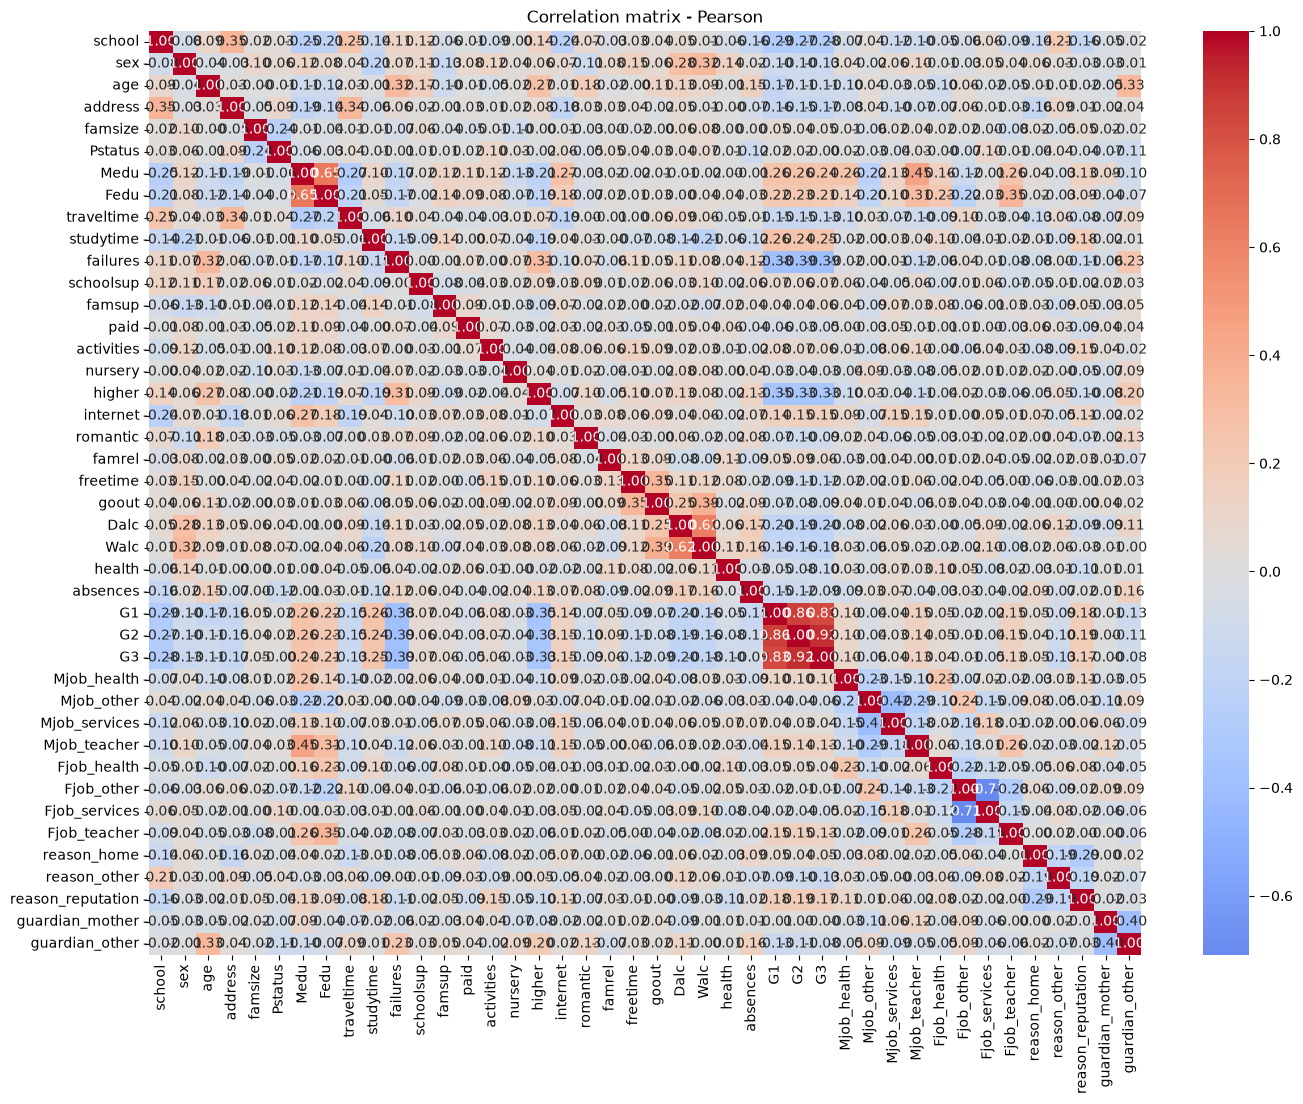

In [6]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation matrix - Pearson")
plt.show()

Spearman

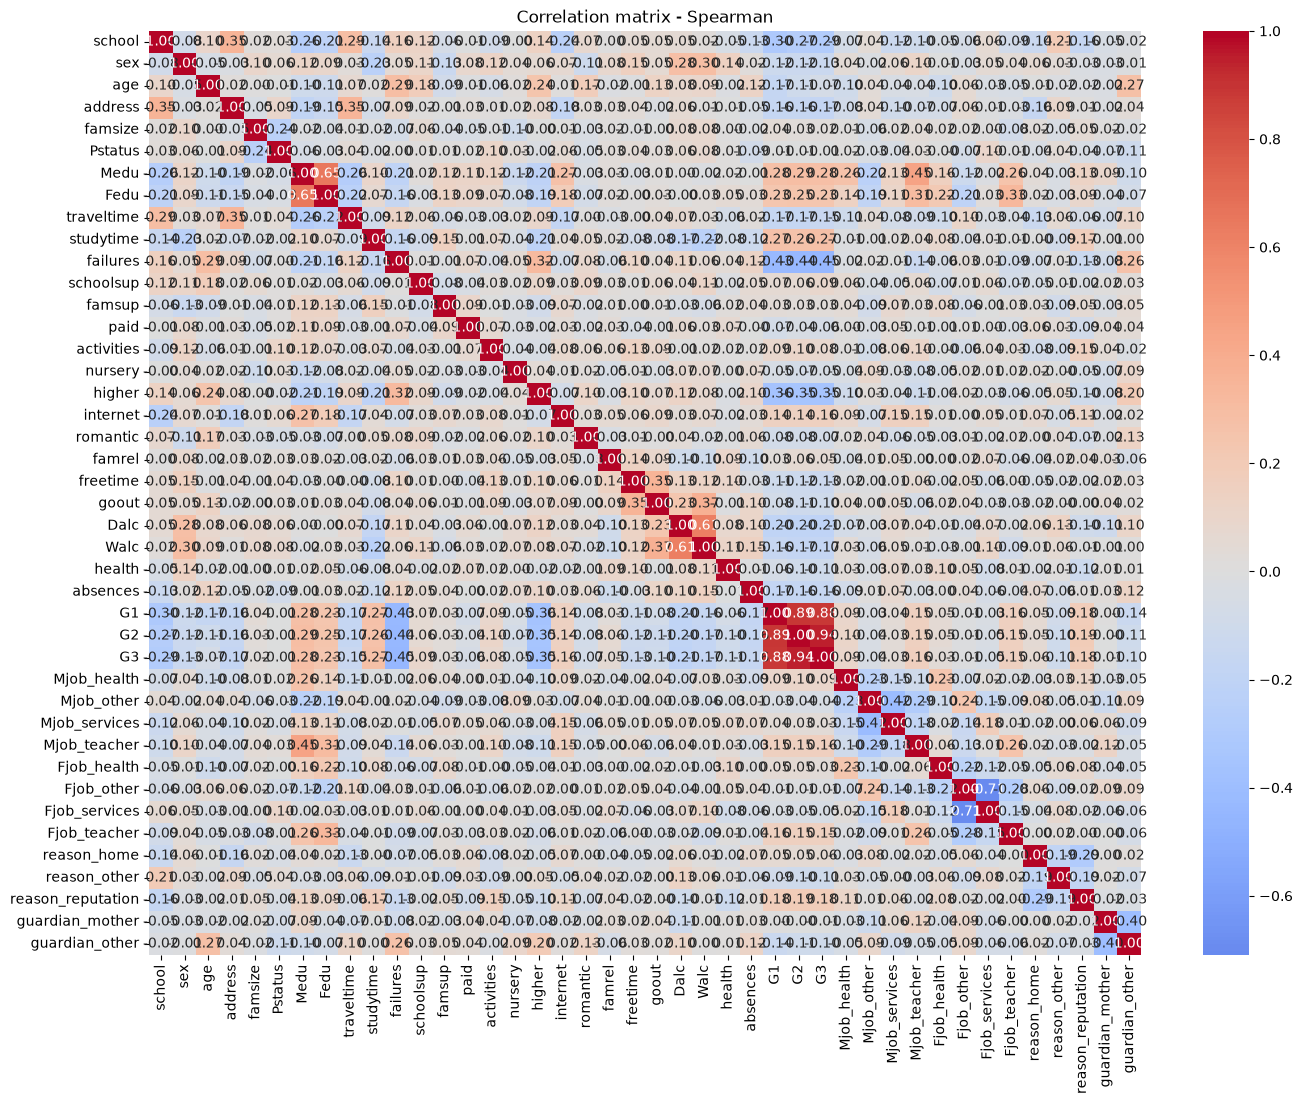

In [7]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation matrix - Spearman")
plt.show()

## Correlation with target variable

First, let's distinguish variables in categories and then we can calculate the most appropriate coefficient

In [8]:
continuous = [
    "age",
    "failures",
    "absences",
    "G3",
    "G2",
    "G1"
]

ordinal = [
    "Medu",
    "Fedu",
    "traveltime",
    "studytime",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health"
]

binary = [
    "school",
    "sex",
    "address",
    "famsize",
    "Pstatus",
    "schoolsup",
    "famsup",
    "paid",
    "activities",
    "nursery",
    "higher",
    "internet",
    "romantic"
]

ohe = [
    x for x in df.columns.to_list()
    if x not in (continuous + ordinal + binary)
    ]

The only time the Spearman coefficient is more reliable is for ordinal variables

In [9]:
pearson_variables = continuous + binary + ohe

pearson_results = (
    df[pearson_variables]
    .corr(method="pearson")["G3"]
    .sort_values(key=abs, ascending=False)
)

spearman_results = (
    df[ordinal + ["G3"]]
    .corr(method="spearman")["G3"]
    .sort_values(key=abs, ascending=False)
)

print("PEARSON")
print(pearson_results)

print("\nSPEARMAN")
print(spearman_results)

PEARSON
G3                   1.000000
G2                   0.918548
G1                   0.826387
failures            -0.393316
higher              -0.332172
school              -0.284294
reason_reputation    0.170944
address             -0.167637
internet             0.150025
Mjob_teacher         0.134910
reason_other        -0.132577
sex                 -0.129077
Fjob_teacher         0.125916
age                 -0.106505
Mjob_health          0.101244
absences            -0.091379
romantic            -0.090583
guardian_other      -0.080729
schoolsup            0.066405
activities           0.059791
Mjob_other          -0.059251
famsup               0.059206
paid                -0.054898
Fjob_services       -0.053204
reason_home          0.046537
famsize              0.045016
Fjob_health          0.039142
Mjob_services        0.038447
nursery             -0.028752
Fjob_other          -0.005301
guardian_mother     -0.004415
Pstatus             -0.000754
Name: G3, dtype: float64

SPEARM

# Feature selection

Variables will be selected according to the following criteria:
* absolute value > 0.10 (at least weak correlation)
* category

In [26]:
pearson_spearman = pd.concat(
    [(pearson_results[abs(pearson_results) > 0.1]),
    (spearman_results[abs(spearman_results) > 0.1])]
).drop_duplicates().sort_values(key=abs, ascending=False).rename("correlation_index")

The category is imported from an Excel file in the documentation

In [ ]:
documentation = pd.read_excel("documentation/documentation.xlsx",
    sheet_name="pre_processed",
    usecols="A,E"
)
feature_selection = pd.merge(documentation, pearson_spearman,
    left_on="Name", 
    right_index=True, 
    how="right")

Manual correction of Category after One Hot Encoding

In [52]:
display(feature_selection.loc[feature_selection.isna().any(axis=1)])
feature_selection.loc[feature_selection["Name"] == "reason_reputation", "Category"] = "habits"
feature_selection.loc[feature_selection["Name"] == "Mjob_teacher", "Category"] = "family"
feature_selection.loc[feature_selection["Name"] == "reason_other", "Category"] = "habits"
feature_selection.loc[feature_selection["Name"] == "Fjob_teacher", "Category"] = "family"
feature_selection.loc[feature_selection["Name"] == "Mjob_health", "Category"] = "family"

,Name,Category,correlation_index
NaN,reason_reputation,NaN,0.170944
NaN,Mjob_teacher,NaN,0.134910
NaN,reason_other,NaN,-0.132577
NaN,Fjob_teacher,NaN,0.125916
NaN,Mjob_health,NaN,0.101244


Only top 5 features of each category, except Targets.\
Candidate features are also saved in lists

In [ ]:
feature_selection = feature_selection.loc[feature_selection["Category"] != "target"]
features = {}

for cat in feature_selection["Category"].unique():
    print(f"Category: {cat}")
    display(feature_selection.loc[feature_selection["Category"] == cat].head(5))
    features[f"{cat}"] = feature_selection.loc[feature_selection["Category"] == cat, "Name"].head(5).to_list()

Category: school


,Name,Category,correlation_index
14.0,failures,school,-0.393316
0.0,school,school,-0.284294
13.0,studytime,school,0.274712


Category: habits


,Name,Category,correlation_index
20.0,higher,habits,-0.332172
26.0,Dalc,habits,-0.208394
NaN,reason_reputation,habits,0.170944
27.0,Walc,habits,-0.170895
NaN,reason_other,habits,-0.132577


Category: family


,Name,Category,correlation_index
6.0,Medu,family,0.283925
7.0,Fedu,family,0.234633
3.0,address,family,-0.167637
21.0,internet,family,0.150025
12.0,traveltime,family,-0.146948


Category: individual


,Name,Category,correlation_index
1.0,sex,individual,-0.129077
2.0,age,individual,-0.106505


As mentioned, the dependent variable will be G3 (final grade).\
Independent variables will be chosen according to the model:
* simple linear regression
    * G2 = the continuous variable with higher correlation, used as an example
* multiple linear regression (individual + school-related factors)
    * max 5 factors
    * sex, age
    * failures, school, studytime
* multiple linear regression (adding family-related factors)
    * Medu, Fedu, address, internet
* multiple linear regression (adding external factors)
    * higher, reason_reputation, Dalc

*`Note`: G2 and G1 are highly correlated with G3, but they are not considered as useful as other variables for predictions*